<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A0_10_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Ольховенко Михайло Валерійович
**Група:** ФІТ 4-8  
**Дата:** 19.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [20]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import keras_tuner as kt
import tensorflow as tf
import os
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "tf.keras")
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2
NumPy: 2.4.6


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Назви класів
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Розміри масивів
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("Кількість класів:", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

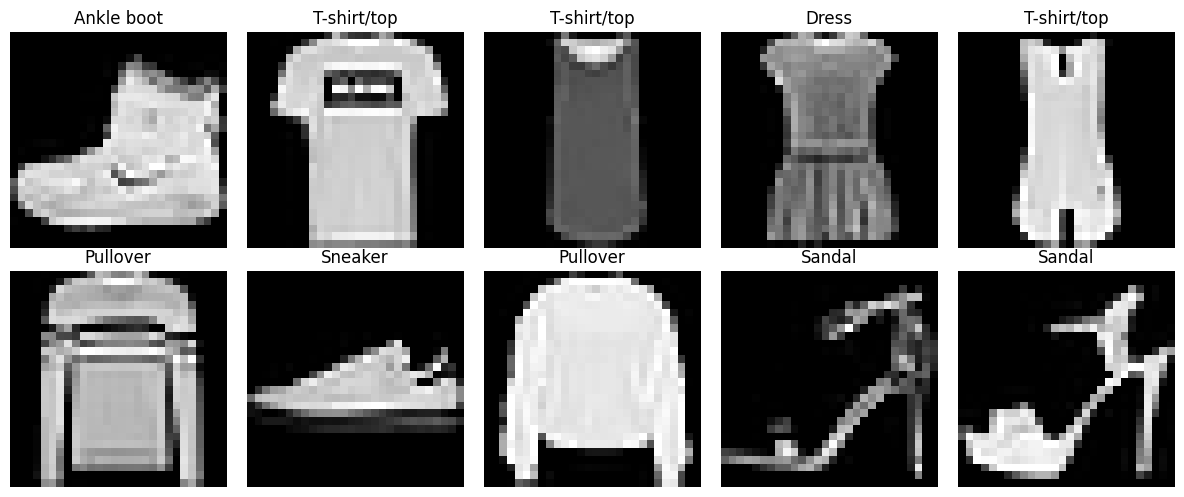

In [5]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("Тип даних:", x_train.dtype)

Мінімальне значення: 0.0
Максимальне значення: 1.0
Тип даних: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [7]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),

    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

# Компіляція моделі
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [8]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

# Навчання моделі
history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.7789 - loss: 0.6253 - val_accuracy: 0.8448 - val_loss: 0.4257 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8457 - loss: 0.4282 - val_accuracy: 0.8602 - val_loss: 0.3781 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8610 - loss: 0.3861 - val_accuracy: 0.8652 - val_loss: 0.3664 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8681 - loss: 0.3606 - val_accuracy: 0.8716 - val_loss: 0.3456 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8742 - loss: 0.3408 - val_accuracy: 0.8766 - val_loss: 0.3377 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8802 - loss: 0.3280 - val_accuracy: 0.8771 - val_loss: 0.3315 - learning_rate: 0.0010
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8829 - loss: 0.

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [9]:
model.summary()

print("\nКількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [10]:
model.save("fashion_mnist_model.keras")

print("Модель успішно збережена!")

Модель успішно збережена!


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

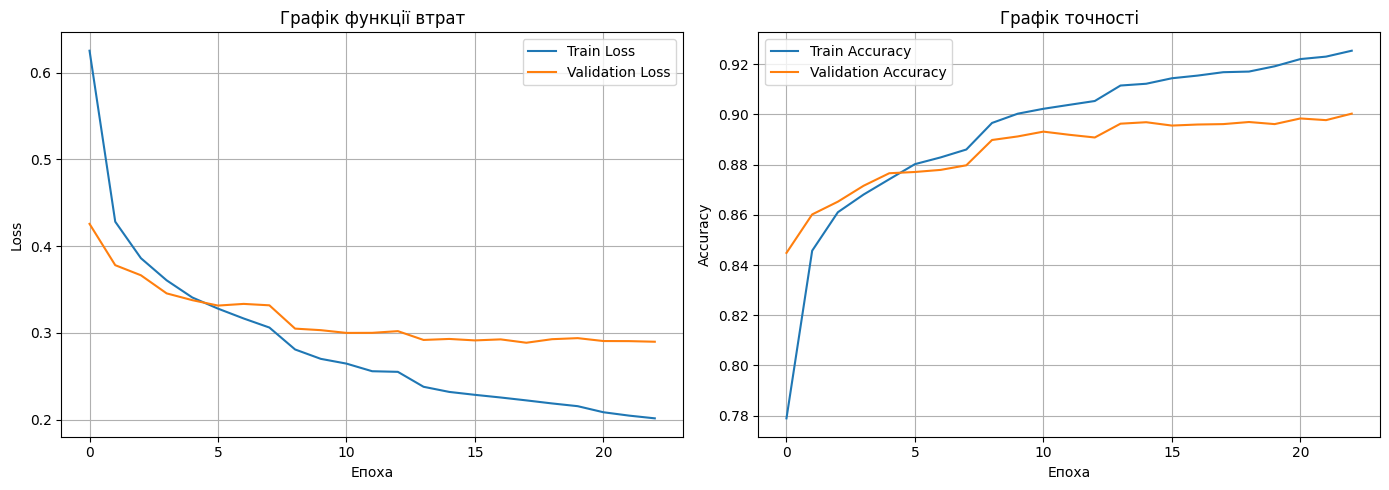

In [11]:
plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Графік функції втрат")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Графік точності")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

# Прогнозування класів
y_pred_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Класифікаційний звіт
print("\nКласифікаційний звіт:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

Test Loss: 0.3175
Test Accuracy: 0.8904
Test Accuracy (%): 89.04 %

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8490    0.8380    0.8435      1000
     Trouser     0.9889    0.9760    0.9824      1000
    Pullover     0.7915    0.8200    0.8055      1000
       Dress     0.8888    0.9030    0.8958      1000
        Coat     0.7944    0.8190    0.8065      1000
      Sandal     0.9719    0.9690    0.9705      1000
       Shirt     0.7345    0.6890    0.7110      1000
     Sneaker     0.9359    0.9630    0.9492      1000
         Bag     0.9741    0.9760    0.9750      1000
  Ankle boot     0.9734    0.9510    0.9621      1000

    accuracy                         0.8904     10000
   macro avg     0.8902    0.8904    0.8902     10000
weighted avg     0.8902    0.8904    0.8902     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

In [13]:
cm = confusion_matrix(y_test, y_pred)

# Кількість помилок для кожного класу
errors_per_class = cm.sum(axis=1) - np.diag(cm)

print("Кількість помилок за класами:")

for i, name in enumerate(class_names):
    print(f"{name}: {errors_per_class[i]}")

# Клас з найбільшою кількістю помилок
worst_class = np.argmax(errors_per_class)

print("\nНайбільше помилок у класі:", class_names[worst_class])
print("Кількість помилок:", errors_per_class[worst_class])


Кількість помилок за класами:
T-shirt/top: 162
Trouser: 24
Pullover: 180
Dress: 97
Coat: 181
Sandal: 31
Shirt: 311
Sneaker: 37
Bag: 24
Ankle boot: 49

Найбільше помилок у класі: Shirt
Кількість помилок: 311


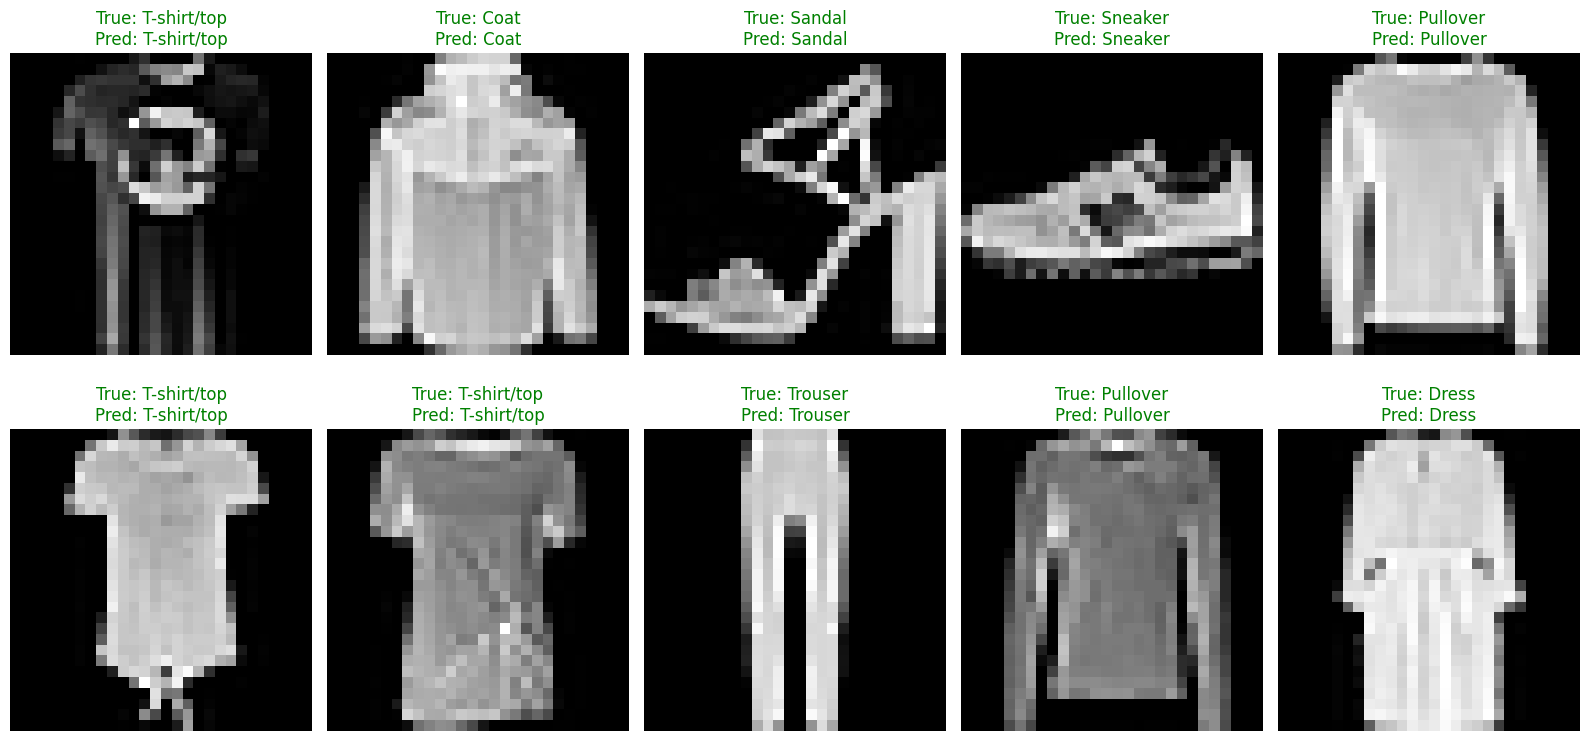

In [14]:
plt.figure(figsize=(16, 8))

# Вибираємо 10 зображень для відображення
indices = np.random.default_rng(42).choice(len(x_test), 10, replace=False)

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)

    # Відображення зображення
    plt.imshow(x_test[idx], cmap="gray")

    # Справжній та прогнозований класи
    true_label = class_names[y_test[idx]]
    predicted_label = class_names[y_pred[idx]]

    # Колір залежить від правильності прогнозу
    color = "green" if y_test[idx] == y_pred[idx] else "red"

    plt.title(
        f"True: {true_label}\nPred: {predicted_label}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
У ході виконання завдання було створено та навчено нейронну мережу для класифікації зображень набору Fashion MNIST. Модель показала тестову точність 0.8904. Найбільше помилок було допущено під час класифікації класів Shirt, що пояснюється схожістю їхніх зовнішніх ознак. Для навчання моделі використовувалися повнозв'язні шари з функцією активації ReLU, Dropout для зменшення перенавчання та оптимізатор Adam. Для контролю навчання було застосовано EarlyStopping і ReduceLROnPlateau. Вимогу щодо точності не нижче 87% виконано, оскільки отримане значення Accuracy перевищує встановленний поріг.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [15]:
!pip install -q keras-tuner

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [17]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Нормалізація пікселів
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Поділ навчальних даних на train та validation
x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", x_train_tuner.shape)
print("Валідаційна вибірка:", x_val_tuner.shape)
print("Тестова вибірка:", x_test.shape)

Навчальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [18]:
def build_model(hp):
    model = keras.Sequential()

    model.add(layers.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    # Підбір кількості прихованих шарів (1-3)
    num_layers = hp.Int("num_layers", min_value=1, max_value=3)

    # Підбір кількості нейронів у кожному шарі
    for i in range(num_layers):
        units = hp.Int(
            f"units_{i}",
            min_value=32,
            max_value=512,
            step=32
        )

        model.add(layers.Dense(
            units,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                hp.Choice("l2", [0.0001, 0.001, 0.01])
            )
        ))

        # Підбір Dropout
        dropout_rate = hp.Choice(
            f"dropout_{i}",
            [0.1, 0.2, 0.3, 0.4, 0.5]
        )

        model.add(layers.Dropout(dropout_rate))

    # Вихідний шар для 10 класів
    model.add(layers.Dense(10, activation="softmax"))

    # Підбір швидкості навчання
    learning_rate = hp.Choice(
        "learning_rate",
        [0.01, 0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [21]:
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="fashion_mnist_tuner",
    project_name="random_search"
)

# Виведення простору пошуку
tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
dropout_0 (Choice)
{'default': 0.1, 'conditions': [], 'values': [0.1, 0.2, 0.3, 0.4, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [22]:
early_stop_tuner = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr_tuner = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

tuner.search(
    x_train_tuner,
    y_train_tuner,
    epochs=30,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[early_stop_tuner, reduce_lr_tuner],
    verbose=1
)

Trial 3 Complete [00h 02m 47s]
val_accuracy: 0.8899999856948853

Best val_accuracy So Far: 0.893583357334137
Total elapsed time: 00h 09m 27s


In [24]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
for name, value in best_hp.values.items():
    print(f"{name}: {value}")

Найкращі гіперпараметри:
num_layers: 3
units_0: 416
l2: 0.0001
dropout_0: 0.4
learning_rate: 0.001
units_1: 32
dropout_1: 0.1
units_2: 32
dropout_2: 0.1


In [25]:
best_model = tuner.hypermodel.build(best_hp)

# Повторне навчання найкращої конфігурації
history_tuner = best_model.fit(
    x_train_tuner,
    y_train_tuner,
    epochs=50,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[early_stop_tuner, reduce_lr_tuner],
    verbose=1
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.7240 - loss: 0.8425 - val_accuracy: 0.8331 - val_loss: 0.5209 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8195 - loss: 0.5670 - val_accuracy: 0.8542 - val_loss: 0.4558 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8403 - loss: 0.5123 - val_accuracy: 0.8619 - val_loss: 0.4402 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8485 - loss: 0.4906 - val_accuracy: 0.8615 - val_loss: 0.4386 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8562 - loss: 0.4690 - val_accuracy: 0.8712 - val_loss: 0.4167 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8579 - loss: 0.4594 - val_accuracy: 0.8728 - val_loss: 0.4142 - learning_rate: 0.0010
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8640 - loss: 

In [26]:
best_model.summary()

print("\nКількість шарів:", len(best_model.layers))
print("Кількість параметрів:", best_model.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 416)            │       326,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │        13,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,023,872 (3.91 MB)

 Trainable params: 341,290 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 682,582 (2.60 MB)


Кількість шарів: 8
Кількість параметрів: 341290


### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

In [27]:
test_loss_tuner, test_accuracy_tuner = best_model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss_tuner, 4))
print("Test Accuracy:", round(test_accuracy_tuner, 4))
print("Test Accuracy (%):", round(test_accuracy_tuner * 100, 2), "%")

Test Loss: 0.3669
Test Accuracy: 0.8915
Test Accuracy (%): 89.15 %


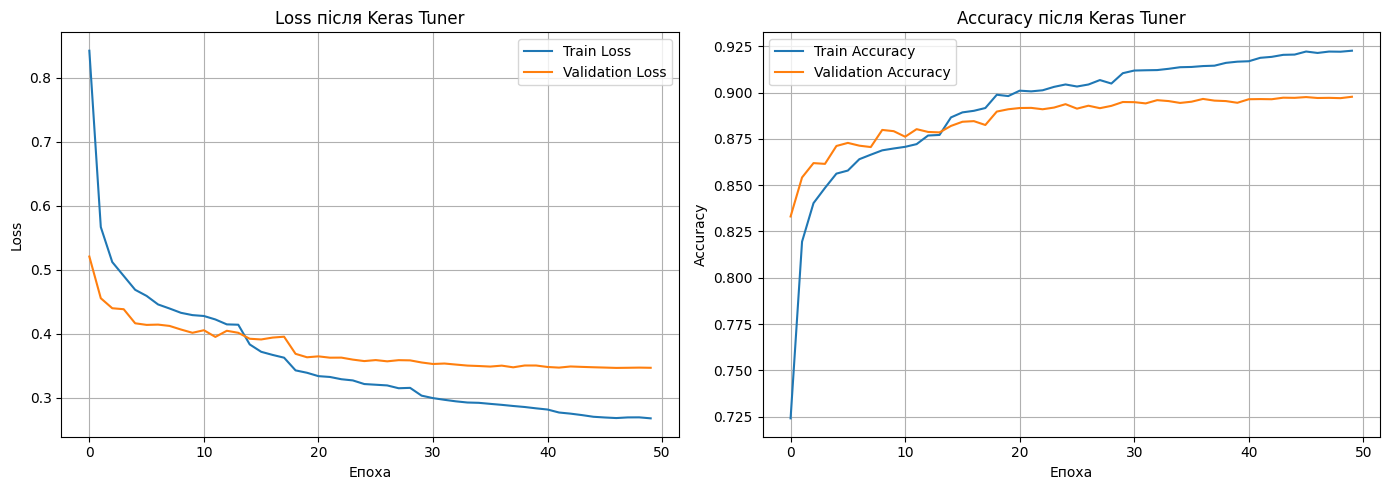

In [28]:
plt.figure(figsize=(14, 5))

# Графік Loss
plt.subplot(1, 2, 1)
plt.plot(history_tuner.history["loss"], label="Train Loss")
plt.plot(history_tuner.history["val_loss"], label="Validation Loss")
plt.title("Loss після Keras Tuner")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Графік Accuracy
plt.subplot(1, 2, 2)
plt.plot(history_tuner.history["accuracy"], label="Train Accuracy")
plt.plot(history_tuner.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy після Keras Tuner")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

task1_accuracy = 0.8915
task1_loss = 0.3669
task1_epochs = 50

# Параметри моделі із завдання 1
task1_layers = 2
task1_neurons = "256, 128"
task1_lr = 0.001

# Параметри моделі після Keras Tuner
best_num_layers = best_hp.get("num_layers")

best_neurons = [
    best_hp.get(f"units_{i}")
    for i in range(best_num_layers)
]

best_lr = best_hp.get("learning_rate")
epochs_tuner = len(history_tuner.history["loss"])

comparison = pd.DataFrame({
    "Показник": [
        "Кількість прихованих шарів",
        "Кількість нейронів",
        "Швидкість навчання",
        "Accuracy на тестовій вибірці",
        "Loss на тестовій вибірці",
        "Кількість епох навчання"
    ],
    "Модель із завдання 1": [
        task1_layers,
        task1_neurons,
        task1_lr,
        task1_accuracy,
        task1_loss,
        task1_epochs
    ],
    "Модель після Keras Tuner": [
        best_num_layers,
        str(best_neurons),
        best_lr,
        round(test_accuracy_tuner, 4),
        round(test_loss_tuner, 4),
        epochs_tuner
    ]
})

display(comparison)

,Показник,Модель із завдання 1,Модель після Keras Tuner
0,Кількість прихованих шарів,2,3
1,Кількість нейронів,"256, 128","[416, 32, 32]"
2,Швидкість навчання,0.001,0.001
3,Accuracy на тестовій вибірці,0.8915,0.8915
4,Loss на тестовій вибірці,0.3669,0.3669
5,Кількість епох навчання,50,50


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.
|Показник|Модель із завдання 1|Модель після Keras Tuner|
|---|---|---|
|Кількість прихованих шарів|2|3|
|Кількість нейронів|256, 128|\[416, 32, 32\]|
|Швидкість навчання|0\.001|0\.001|
|Accuracy на тестовій вибірці|0\.8915|0\.8915|
|Loss на тестовій вибірці|0\.3669|0\.3669|
|Кількість епох навчання|50|50|
|---|---|---|

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У другому завданні було виконано автоматизований добір гіперпараметрів нейронної мережі за допомогою Keras Tuner та алгоритму RandomSearch. У процесі пошуку перевірялися різні конфігурації кількості прихованих шарів, нейронів, Dropout, L2-регуляризації та швидкості навчання. Найкраща модель містить три приховані Dense-шари з 416, 32 та 32 нейронами. Тестова точність моделі становила 89,15%, а значення функції втрат — 0,3669. Валідаційна точність під час пошуку досягла 89,36%. Таким чином, модель успішно виконує завдання класифікації Fashion MNIST та перевищує встановлений поріг точності 87%.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.